In [41]:
import numpy as np

basemva = 100
accuracy = 0.001
accel = 1.8
maxiter = 200

### Barra tipo **1**
Este código é usado para o barramento slack (swing). A única informação necessária para este barramento é a magnitude da tensão e seu ângulo de fase.


### Barra tipo **0**
Este código é usado para barramentos de carga. As cargas são inseridas positivamente em megawatts e megavars. Para este barramento, deve ser especificada uma estimativa inicial de tensão. Isso é normalmente 1 e 0 para magnitude de tensão e ângulo de fase, respectivamente. Se a magnitude da tensão e o ângulo de fase para este tipo de barramento forem especificados, eles serão considerados como a tensão inicial de partida para esse barramento, em vez de um início plano de 1 e 0.


### Barra tipo **2**
Este código é usado para os barramentos controlados por tensão. Para este barramento, devem ser especificados a magnitude da tensão, a geração de energia real em megawatts e os limites mínimos e máximos da demanda de megavar.

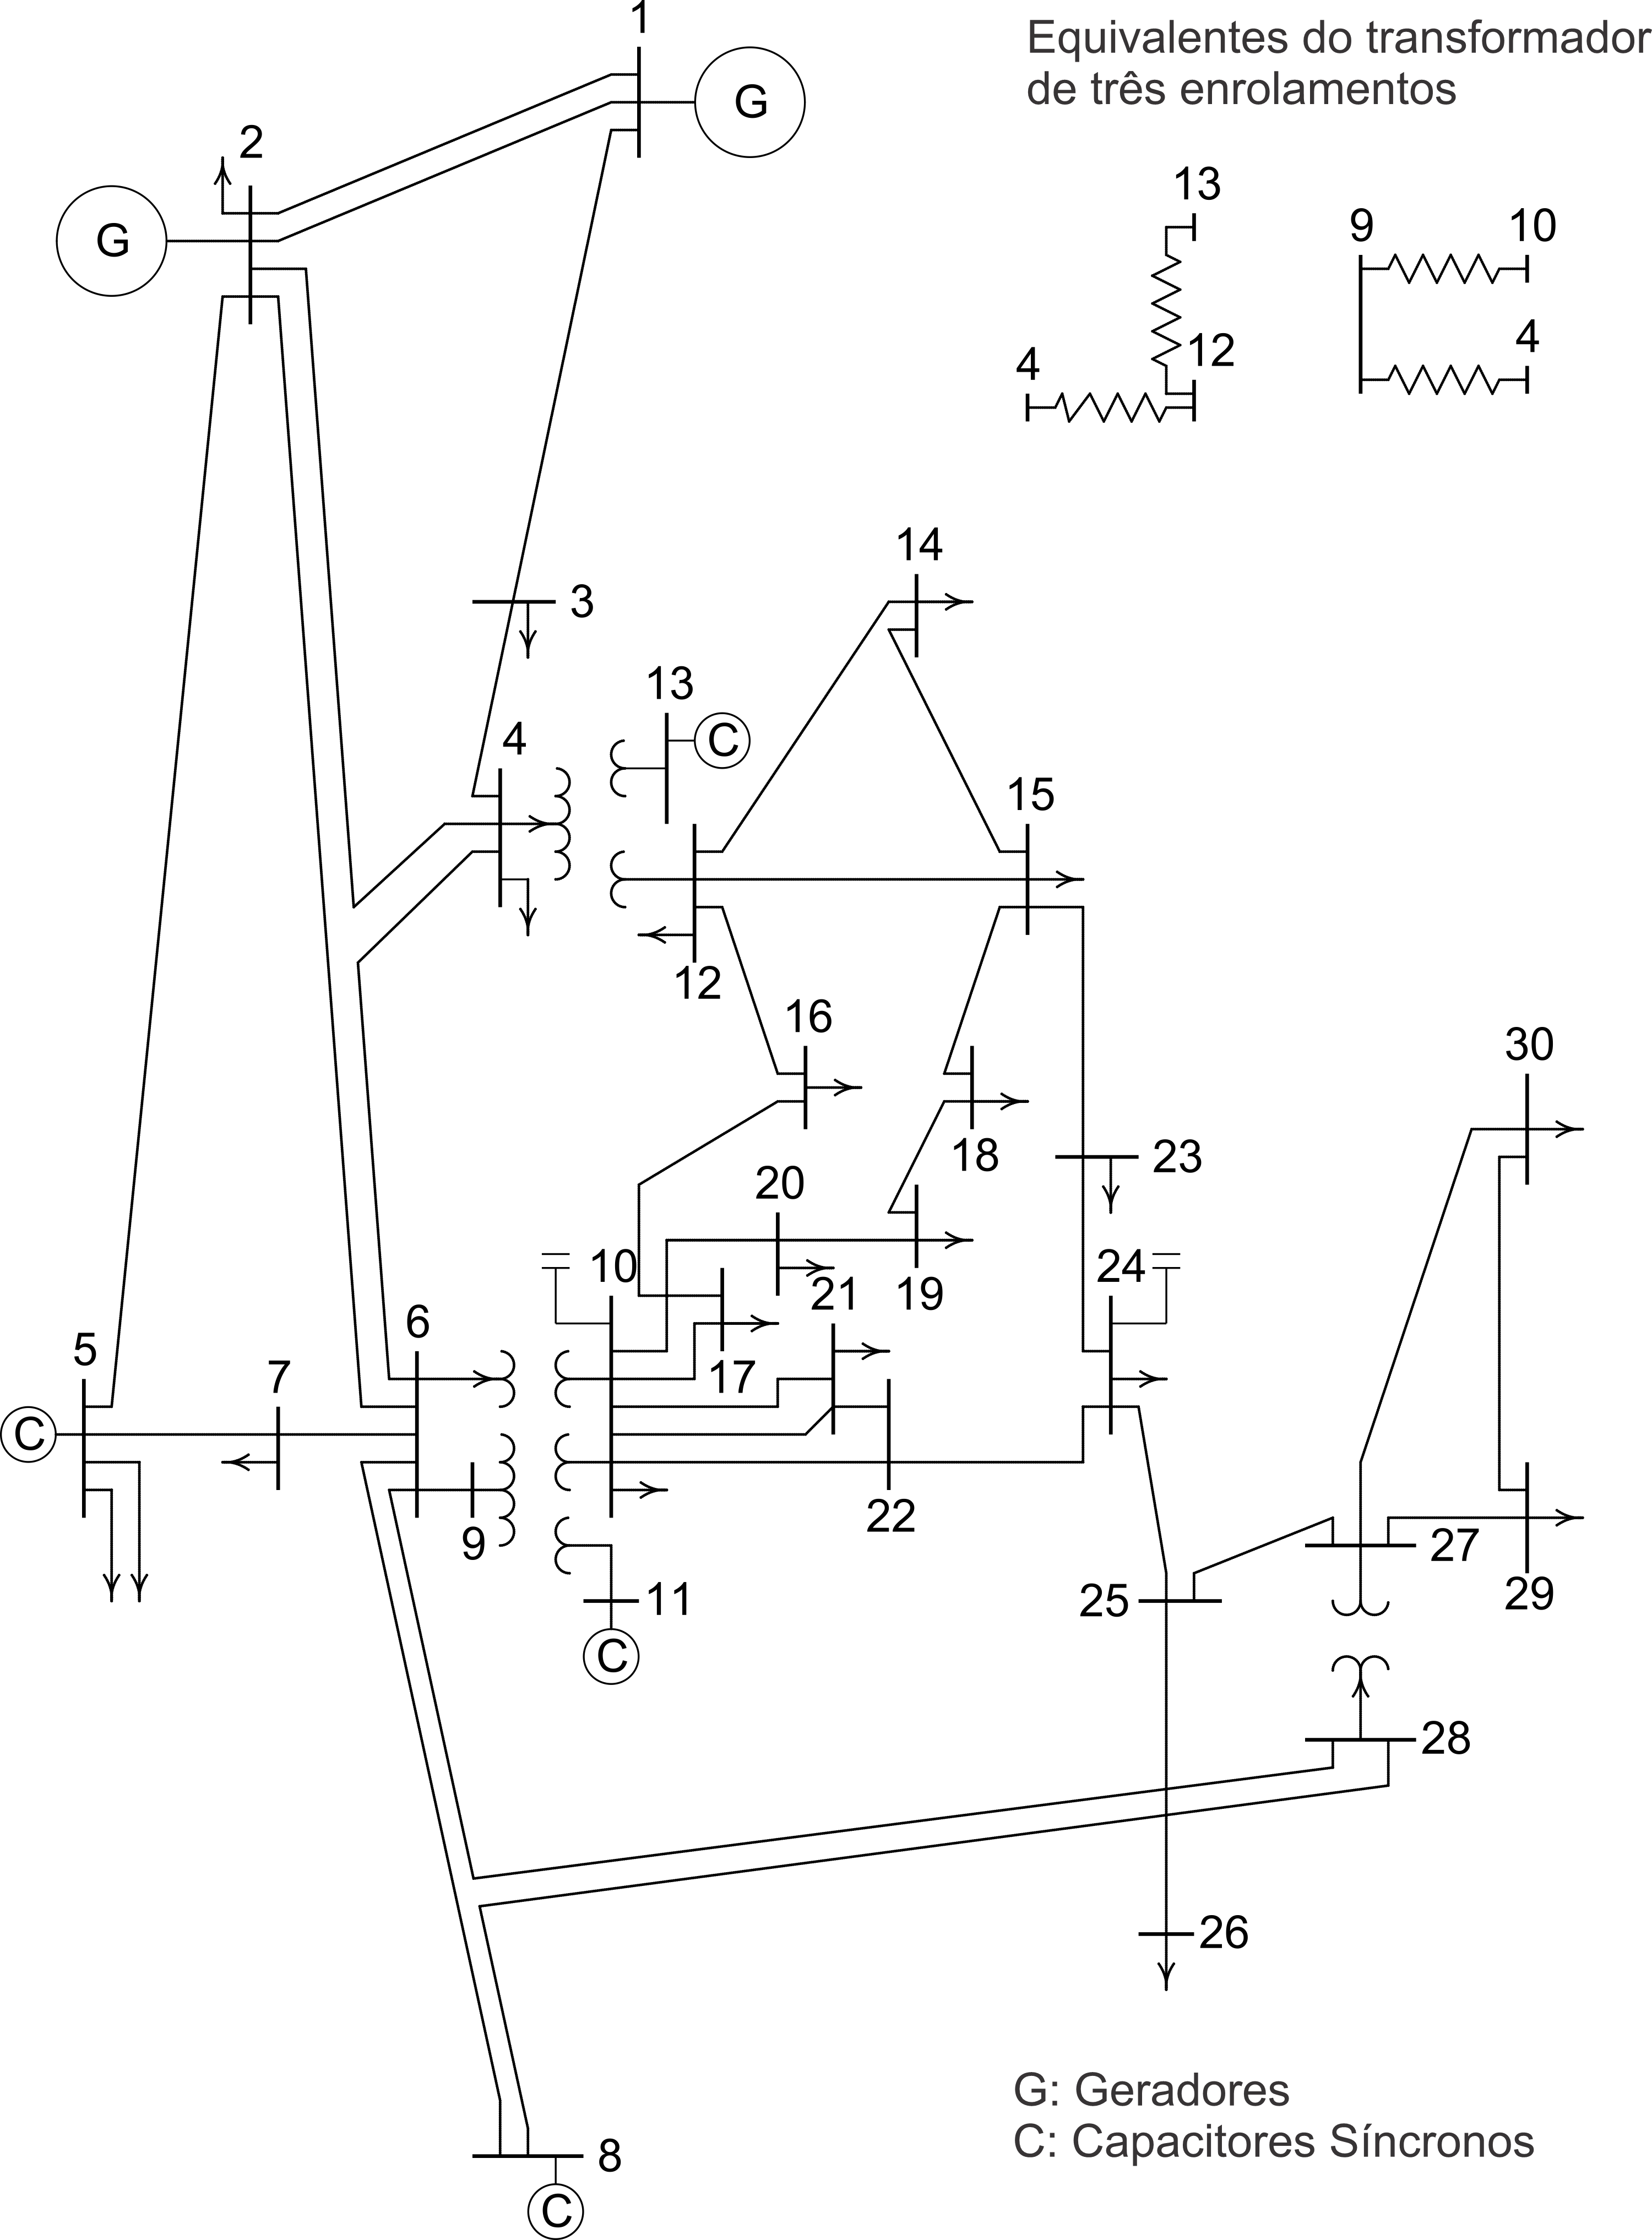

In [42]:
#    IEEE 30-BUS TEST SYSTEM (American Electric Power)
#    Bus Bus  Voltage Angle   ---Load----   -Generator- -Static Mvar
#    No  type  Mag.   Degree  MW     Mvar   MW    Mvar   Qmin Qmax  +Qc/-Ql
busdata = np.array([
    [1,   1,   1.06,   0.0,   0.0,   0.0,   0.0,   0.0,   0,   0,   0],
    [2,   2,   1.043,  0.0,   21.70, 12.7,  40.0,  0.0,  -40,  50,  0],
    [3,   0,   1.0,    0.0,   2.4,   1.2,   0.0,   0.0,   0,   0,   0],
    [4,   0,   1.06,   0.0,   7.6,   1.6,   0.0,   0.0,   0,   0,   0],
    [5,   2,   1.01,   0.0,   94.2,  19.0,  0.0,   0.0,  -40,  40,  0],
    [6,   0,   1.0,    0.0,   0.0,   0.0,   0.0,   0.0,   0,   0,   0],
    [7,   0,   1.0,    0.0,   22.8,  10.9,  0.0,   0.0,   0,   0,   0],
    [8,   2,   1.01,   0.0,   30.0,  30.0,  0.0,   0.0,  -30,  40,  0],
    [9,   0,   1.0,    0.0,   0.0,   0.0,   0.0,   0.0,   0,   0,   0],
    [10,  0,   1.0,    0.0,   5.8,   2.0,   0.0,   0.0,  -6,   24,  19],
    [11,  2,   1.082,  0.0,   0.0,   0.0,   0.0,   0.0,   0,   0,   0],
    [12,  0,   1.0,    0,     11.2,  7.5,   0,     0,     0,   0,   0],
    [13,  2,   1.071,  0,     0,     0.0,   0,     0,    -6,   24,  0],
    [14,  0,   1,      0,     6.2,   1.6,   0,     0,     0,   0,   0],
    [15,  0,   1,      0,     8.2,   2.5,   0,     0,     0,   0,   0],
    [16,  0,   1,      0,     3.5,   1.8,   0,     0,     0,   0,   0],
    [17,  0,   1,      0,     9.0,   5.8,   0,     0,     0,   0,   0],
    [18,  0,   1,      0,     3.2,   0.9,   0,     0,     0,   0,   0],
    [19,  0,   1,      0,     9.5,   3.4,   0,     0,     0,   0,   0],
    [20,  0,   1,      0,     2.2,   0.7,   0,     0,     0,   0,   0],
    [21,  0,   1,      0,     17.5,  11.2,  0,     0,     0,   0,   0],
    [22,  0,   1,      0,     0,     0.0,   0,     0,     0,   0,   0],
    [23,  0,   1,      0,     3.2,   1.6,   0,     0,     0,   0,   0],
    [24,  0,   1,      0,     8.7,   6.7,   0,     0,     0,   0,   4.3],
    [25,  0,   1,      0,     0,     0.0,   0,     0,     0,   0,   0],
    [26,  0,   1,      0,     3.5,   2.3,   0,     0,     0,   0,   0],
    [27,  0,   1,      0,     0,     0.0,   0,     0,     0,   0,   0],
    [28,  0,   1,      0,     0,     0.0,   0,     0,     0,   0,   0],
    [29,  0,   1,      0,     2.4,   0.9,   0,     0,     0,   0,   0],
    [30,  0,   1,      0,     10.6,  1.9,   0,     0,     0,   0,   0]
])

In [43]:
#    Bus  bus  R       X            1/2 B       = 1 for lines
#    nl   nr   p.u.    p.u.         p.u.        > 1 or < 1 tr. tap at bus nl
linedata = np.array([
    [1,   2,   0.0192, 0.0575,      0.02640,    1],
    [1,   3,   0.0452, 0.1852,      0.02040,    1],
    [2,   4,   0.0570, 0.1737,      0.01840,    1],
    [3,   4,   0.0132, 0.0379,      0.00420,    1],
    [2,   5,   0.0472, 0.1983,      0.02090,    1],
    [2,   6,   0.0581, 0.1763,      0.01870,    1],
    [4,   6,   0.0119, 0.0414,      0.00450,    1],
    [5,   7,   0.0460, 0.1160,      0.01020,    1],
    [6,   7,   0.0267, 0.0820,      0.00850,    1],
    [6,   8,   0.0120, 0.0420,      0.00450,    1],
    [6,   9,   0.0,    0.2080,      0.0,        0.978],
    [6,  10,   0.0,    0.5560,      0.0,        0.969],
    [9,  11,   0.0,    0.2080,      0.0,        1],
    [9,  10,   0.0,    0.1100,      0.0,        1],
    [4,  12,   0.0,    0.2560,      0.0,        0.932],
    [12, 13,   0.0,    0.1400,      0.0,        1],
    [12, 14,   0.1231, 0.2559,      0.0,        1],
    [12, 15,   0.0662, 0.1304,      0.0,        1],
    [12, 16,   0.0945, 0.1987,      0.0,        1],
    [14, 15,   0.2210, 0.1997,      0.0,        1],
    [16, 17,   0.0824, 0.1923,      0.0,        1],
    [15, 18,   0.1073, 0.2185,      0.0,        1],
    [18, 19,   0.0639, 0.1292,      0.0,        1],
    [19, 20,   0.0340, 0.0680,      0.0,        1],
    [10, 20,   0.0936, 0.2090,      0.0,        1],
    [10, 17,   0.0324, 0.0845,      0.0,        1],
    [10, 21,   0.0348, 0.0749,      0.0,        1],
    [10, 22,   0.0727, 0.1499,      0.0,        1],
    [21, 22,   0.0116, 0.0236,      0.0,        1],
    [15, 23,   0.1000, 0.2020,      0.0,        1],
    [22, 24,   0.1150, 0.1790,      0.0,        1],
    [23, 24,   0.1320, 0.2700,      0.0,        1],
    [24, 25,   0.1885, 0.3292,      0.0,        1],
    [25, 26,   0.2544, 0.3800,      0.0,        1],
    [25, 27,   0.1093, 0.2087,      0.0,        1],
    [28, 27,   0.0,    0.3960,      0.0,        0.968],
    [27, 29,   0.2198, 0.4153,      0.0,        1],
    [27, 30,   0.3202, 0.6027,      0.0,        1],
    [29, 30,   0.2399, 0.4533,      0.0,        1],
    [8,  28,   0.0636, 0.2000,      0.0214,     1],
    [6,  28,   0.0169, 0.0599,      0.065,      1]
])

In [44]:
nl = linedata[:, 0]
nr = linedata[:, 1]
R = linedata[:, 2]
X = linedata[:, 3]
Bc = 1j * linedata[:, 4]
a = linedata[:, 5]

nbr = len(linedata[:, 0])
nbus = max(np.max(nl), np.max(nr))
nbus = int(nbus)

In [45]:
Z = R + 1j * X  # branch impedance
y = np.ones(nbr) / Z  # branch admittance

# Adjust tap settings
a[a <= 0] = 1

# Initialize Ybus
Ybus = np.zeros((nbus, nbus), dtype=complex)


### Formação de $Y_{bus}$

In [46]:
for k in range(nbr):
    Ybus[int(nl[k]) - 1, int(nr[k]) - 1] -= y[k] / a[k]
    Ybus[int(nr[k]) - 1, int(nl[k]) - 1] = Ybus[int(nl[k]) - 1, int(nr[k]) - 1]

for n in range(nbus):
    for k in range(nbr):
        if nl[k] == n + 1:
            Ybus[n, n] += y[k] / (a[k]**2) + Bc[k]
        elif nr[k] == n + 1:
            Ybus[n, n] += y[k] + Bc[k]

In [59]:
import numpy as np
import cmath

# Substitua busdata, Ybus, nbr, nl, nr, etc., pelos seus valores ou matrizes equivalentes
# Essas variáveis precisam ser definidas antes de executar este código

# Configuração inicial
nbus = len(busdata[:, 0])
kb = np.zeros(nbus)
Vm = np.zeros(nbus)
delta = np.zeros(nbus)
Pd = np.zeros(nbus)
Qd = np.zeros(nbus)
Pg = np.zeros(nbus)
Qg = np.zeros(nbus)
Qmin = np.zeros(nbus)
Qmax = np.zeros(nbus)
Qsh = np.zeros(nbus)
P = np.zeros(nbus, dtype=complex)
Q = np.zeros(nbus, dtype=complex)
S = np.zeros(nbus, dtype=complex)
V = np.zeros(nbus, dtype=complex)
DV = np.zeros(nbus)

for k in range(nbus):
    n = int(busdata[k, 0]) - 1
    kb[n], Vm[n], delta[n] = busdata[k, 1:4]
    Pd[n], Qd[n], Pg[n], Qg[n], Qmin[n], Qmax[n] = busdata[k, 4:10]
    Qsh[n] = busdata[k, 10]
    if Vm[n] <= 0:
        V[n] = 1 + 0j
    else:
        delta[n] = np.radians(delta[n])
        V[n] = Vm[n] * (np.cos(delta[n]) + 1j * np.sin(delta[n]))
        P[n] = (Pg[n] - Pd[n]) / basemva
        Q[n] = (Qg[n] - Qd[n] + Qsh[n]) / basemva
        S[n] = P[n] + 1j * Q[n]

# Configuração para linhas paralelas
mline = np.ones(nbr)
for k in range(nbr):
    for m in range(k + 1, nbr):
        if (nl[k] == nl[m] and nr[k] == nr[m]) or (nl[k] == nr[m] and nr[k] == nl[m]):
            mline[m] = 2

# Valores padrão
accel = 1.3
accuracy = 0.001
basemva = 100
maxiter = 100


# Iterações do Gauss-Seidel
iter = 0
maxerror = 10
while maxerror >= accuracy and iter <= maxiter:
    iter += 1
    for n in range(nbus):
        YV = 0 + 0j
        for L in range(nbr):
            if nl[L] == n + 1 and mline[L] == 1:
                k = nr[L] - 1
                YV += Ybus[int(n), int(k)] * V[int(k)]
            elif nr[L] == n + 1 and mline[L] == 1:
                k = nl[L] - 1
                YV += Ybus[n, k] * V[k]

        Sc = np.conj(V[n]) * (Ybus[n, n] * V[n] + YV)
        Sc = np.conj(Sc)
        DP = P[n] - Sc.real
        DP = DP.real
        DQ = Q[n] - Sc.imag
        DQ = DQ.real
        print(DP)
        print(DQ)
        if kb[n] == 1:
            S[n] = Sc
            P[n] = Sc.real
            Q[n] = Sc.imag
            DP[n] = 0.0
            DQ[n] = 0.0
            Vc = V[n]
        elif kb[n] == 2:
            Q[n] = Sc.imag
            S[n] = P[n] + 1j * Q[n]

            if Qmax[n] != 0:
                Qgc = Q[n] * basemva + Qd[n] - Qsh[n]
                if abs(DQ[n]) <= 0.005 and iter >= 10:
                    if DV[n] <= 0.045:
                        if Qgc < Qmin[n]:
                            Vm[n] += 0.005
                            DV[n] += 0.005
                        elif Qgc > Qmax[n]:
                            Vm[n] -= 0.005
                            DV[n] += 0.005

        if kb[n] != 1:
            Vc = (np.conj(S[n]) / np.conj(V[n]) - YV) / Ybus[n, n]
            if kb[n] == 0:
                V[n] += accel * (Vc - V[n])
            elif kb[n] == 2:
                VcI = np.imag(Vc)
                VcR = np.sqrt(Vm[n]**2 - VcI**2)
                Vc = VcR + 1j * VcI
                V[n] += accel * (Vc - V[n])

    maxerror = max(np.max(np.abs(np.real(DP))), np.max(np.abs(np.imag(DQ))))
    if iter == maxiter and maxerror > accuracy:
        print('\nWARNING: Iterative solution did not converge after {} iterations.\n'.format(iter))
        converge = 0
    else:
        converge = 1

# Pós-processamento
if converge != 1:
    tech = 'ITERATIVE SOLUTION DID NOT CONVERGE'
else:
    tech = 'Power Flow Solution by Gauss-Seidel Method'

for n in range(nbus):
    Vm[n] = np.abs(V[n])
    delta[n] = np.angle(V[n]) * 180 / np.pi
    if kb[n] == 1:
        S[n] = P[n] + 1j * Q[n]
        Pg[n] = P[n] * basemva + Pd[n]
        Qg[n] = Q[n] * basemva + Qd[n] - Qsh[n]
    elif kb[n] == 2:
        S[n] = P[n] + 1j * Q[n]
        Qg[n] = Q[n] * basemva + Qd[n] - Qsh[n]

    yload[n] = (Pd[n] - 1j * Qd[n] + 1j * Qsh[n]) / (basemva * Vm[n]**2)

Pgt = sum(Pg)
Qgt = sum(Qg)
Pdt = sum(Pd)
Qdt = sum(Qd)
Qsht = sum(Qsh)

# Atualize busdata com os resultados finais
busdata[:, 3] = Vm
busdata[:, 4] = delta


-0.1732498156442511
-0.5534764682597284


TypeError: ignored